<a href="https://colab.research.google.com/github/Daudi-Zacharia/MSc_Data_Science/blob/main/Thesis/Classification/cross_dataset_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Cross-Dataset Evaluation

# INFO

This notebook evaluates classification models across the two chest X-ray datasets used in the thesis:

- Models trained on the **4200-image (Rahman)** dataset are evaluated on the **whole 704-image** dataset (train + val + test combined).
- Models trained on the **704-image** dataset are evaluated on the **whole 4200-image** dataset (train + val + test combined).

Five architectures are covered: Custom CNN, DenseNet169, VGG16, ResNet50, EfficientNetB3. Each has its own section below with a confusion matrix, ROC curve and metrics printout for both evaluation directions. The notebook ends with two summary tables (Accuracy, Precision, Sensitivity, F1, Specificity, AUC).

# CONFIGURATION

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# IMPORTS AND INSTALLS

In [2]:
!pip install kagglehub -q
!pip install openpyxl -q

In [6]:
import os
import shutil
import time

import pandas as pd
import numpy as np

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, ConcatDataset
from torchvision import transforms as T
from torchvision.datasets import ImageFolder

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix, f1_score, precision_score, recall_score,
    roc_auc_score, roc_curve
)

# HELPER FUNCTIONS

## Predicting (with confusion matrix, ROC and full metrics)

In [ ]:
def model_predict_new(model, test_data_loader, device):
    """Runs inference over test_data_loader, prints/plots evaluation
    outputs and returns predictions, probabilities, targets and a metrics dict."""

    model.to(device)
    model.eval()
    test_time_start = time.time()

    predictions = []
    actual = []
    all_probs = []

    with torch.no_grad():
        for batch, targets in test_data_loader:
            inputs, outputs = batch.to(device), targets.to(device)
            output = model(inputs)

            predictions.append(output.argmax(dim=1).cpu())
            actual.append(targets.cpu())

            probs = F.softmax(output, dim=1)
            pos_probs = probs[:, 1]
            all_probs.append(pos_probs.cpu())

    test_time = (time.time() - test_time_start) / 60

    combo_predictions = torch.cat(predictions, dim=0)
    combo_targets = torch.cat(actual, dim=0)
    combo_probs = torch.cat(all_probs, dim=0)

    # --- Metrics Calculations ---
    # zero_division=0 makes the ill-defined case explicit (e.g. a model that
    # collapses to predicting a single class under domain shift) instead of
    # raising an UndefinedMetricWarning.
    cm = confusion_matrix(combo_targets.numpy(), combo_predictions.numpy())
    accuracy = (combo_predictions == combo_targets).sum().item() / len(combo_targets)
    f1 = f1_score(combo_targets.numpy(), combo_predictions.numpy(), zero_division=0)
    sens = recall_score(combo_targets.numpy(), combo_predictions.numpy(), zero_division=0)
    prec = precision_score(combo_targets.numpy(), combo_predictions.numpy(), zero_division=0)
    spec = recall_score(combo_targets.numpy(), combo_predictions.numpy(), pos_label=0, zero_division=0)
    auc = roc_auc_score(combo_targets.numpy(), combo_probs.numpy())

    print('Prediction Metrics')
    print(f'Test Accuracy: {accuracy:.4f} | f1: {f1:.4f} | AUC: {auc:.4f}')
    print(f'Sensitivity: {sens:.4f} | Specificity: {spec:.4f}')
    print(f'Precision: {prec:.4f} | Test Time: {test_time:.4f}')

    # --- 1. Confusion Matrix Heatmap ---
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Normal', 'TB'],
                yticklabels=['Normal', 'TB'],
                cbar=False, annot_kws={"size": 16, "weight": "bold"})
    plt.xlabel('Predicted Class', fontsize=12)
    plt.ylabel('True Class', fontsize=12)
    plt.title('Confusion Matrix', fontsize=15, pad=20)
    plt.show()

    # --- 2. ROC Curve ---
    fpr, tpr, _ = roc_curve(combo_targets.numpy(), combo_probs.numpy())
    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc:.4f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate (1 - Specificity)')
    plt.ylabel('True Positive Rate (Sensitivity)')
    plt.title('Receiver Operating Characteristic (ROC)')
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    plt.show()

    metrics = {
        'Acc.': accuracy,
        'Prec.': prec,
        'Sens.': sens,
        'F1': f1,
        'Spec.': spec,
        'AUC': auc,
    }

    return combo_predictions, combo_probs, combo_targets, metrics

## Whole-dataset loader (combines train + val + test)

In [ ]:
def whole_dataset(base_dir, transform):
    """Combines the train, val and test splits of a dataset folder into a
    single dataset covering the whole dataset, using the given transform."""
    parts = [ImageFolder(root=os.path.join(base_dir, split), transform=transform)
             for split in ['train', 'val', 'test']]
    return ConcatDataset(parts)

## Results bookkeeping

In [9]:
# metrics for models trained on the 4200 dataset, evaluated on the whole 704 dataset
results_4200_to_704 = []

# metrics for models trained on the 704 dataset, evaluated on the whole 4200 dataset
results_704_to_4200 = []

def record(results_list, model_name, metrics):
    results_list.append({'Model': model_name, **metrics})

# DATA SETUP

## Download and build the 4200 (Rahman) dataset

In [10]:
import kagglehub

path_rahman = kagglehub.dataset_download("tawsifurrahman/tuberculosis-tb-chest-xray-dataset")
print("Path to dataset files:", path_rahman)

Using Colab cache for faster access to the 'tuberculosis-tb-chest-xray-dataset' dataset.
Path to dataset files: /kaggle/input/tuberculosis-tb-chest-xray-dataset


In [11]:
def create_images_folder_4200(path, base_dir):
    """Splits the 4200 (Rahman) dataset into train/val/test folders
    (80/10/10) under base_dir, mirroring the split used at training time."""

    tb_md = pd.read_excel(os.path.join(path, 'TB_Chest_Radiography_Database', 'Tuberculosis.metadata.xlsx'))
    no_tb_md = pd.read_excel(os.path.join(path, 'TB_Chest_Radiography_Database', 'Normal.metadata.xlsx'))

    img_id1 = list(tb_md['FILE NAME'])
    img_id0 = list(no_tb_md['FILE NAME'])

    print(f'# of TB images: {len(img_id1)}')
    print(f'# of Normal images: {len(img_id0)}')
    print(f'Total: {len(img_id1) + len(img_id0)}')

    train_ratio, val_ratio = 0.8, 0.1

    train_no_1 = int(train_ratio * len(img_id1))
    train_no_0 = int(train_ratio * len(img_id0))
    val_no_1 = int(val_ratio * len(img_id1))
    val_no_0 = int(val_ratio * len(img_id0))

    train_1, train_0 = img_id1[:train_no_1], img_id0[:train_no_0]
    val_1 = img_id1[train_no_1:train_no_1 + val_no_1]
    val_0 = img_id0[train_no_0:train_no_0 + val_no_0]
    test_1 = img_id1[train_no_1 + val_no_1:]
    test_0 = img_id0[train_no_0 + val_no_0:]

    for s in ['train', 'val', 'test']:
        for klas in ['tb', 'no_tb']:
            os.makedirs(os.path.join(base_dir, s, klas), exist_ok=True)

    path_tb_images = os.path.join(path, 'TB_Chest_Radiography_Database', 'Tuberculosis')
    path_no_tb_images = os.path.join(path, 'TB_Chest_Radiography_Database', 'Normal')

    tasks = [
        (train_1, 'train', 'tb', path_tb_images),
        (val_1,   'val',   'tb', path_tb_images),
        (test_1,  'test',  'tb', path_tb_images),
        (train_0, 'train', 'no_tb', path_no_tb_images),
        (val_0,   'val',   'no_tb', path_no_tb_images),
        (test_0,  'test',  'no_tb', path_no_tb_images),
    ]

    print("Copying images...")
    for ids, folder, klas, source_dir in tasks:
        for i in ids:
            str_i = str(i) + '.png'
            shutil.copy(
                src=os.path.join(source_dir, str_i),
                dst=os.path.join(base_dir, folder, klas, str_i)
            )

    print(f'Successfully created {base_dir}/train, {base_dir}/val, {base_dir}/test')

create_images_folder_4200(path_rahman, base_dir='./data_4200')

# of TB images: 700
# of Normal images: 3500
Total: 4200
Copying images...
Successfully created ./data_4200/train, ./data_4200/val, ./data_4200/test


## Download and build the 704 dataset

In [12]:
path_704 = kagglehub.dataset_download("iamtapendu/chest-x-ray-lungs-segmentation")
print("Path to dataset files:", path_704)

100%|██████████| 3.59G/3.59G [00:35<00:00, 110MB/s] 

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/iamtapendu/chest-x-ray-lungs-segmentation/versions/1


In [13]:
def create_split_folders_704(path, base_dir):
    """Splits the 704 dataset into train/val/test folders (70/20/10) under
    base_dir, mirroring the split used at training time."""

    metadata = pd.read_csv(os.path.join(path, 'MetaData.csv'))

    img_id1 = list(metadata['id'][metadata['ptb'] == 1])
    img_id0 = list(metadata['id'][metadata['ptb'] == 0])

    print(f'# of TB images: {len(img_id1)}')
    print(f'# of Normal images: {len(img_id0)}')
    print(f'Total: {len(img_id1) + len(img_id0)}')

    train_ratio, val_ratio = 0.7, 0.2

    train_no_1 = int(train_ratio * len(img_id1))
    train_no_0 = int(train_ratio * len(img_id0))
    val_no_1 = int(val_ratio * len(img_id1))
    val_no_0 = int(val_ratio * len(img_id0))

    train_1, train_0 = img_id1[:train_no_1], img_id0[:train_no_0]
    val_1 = img_id1[train_no_1:train_no_1 + val_no_1]
    val_0 = img_id0[train_no_0:train_no_0 + val_no_0]
    test_1 = img_id1[train_no_1 + val_no_1:]
    test_0 = img_id0[train_no_0 + val_no_0:]

    for s in ['train', 'val', 'test']:
        for klas in ['tb', 'no_tb']:
            os.makedirs(os.path.join(base_dir, s, klas), exist_ok=True)

    path_images = os.path.join(path, 'Chest-X-Ray/Chest-X-Ray/image')

    tasks = [
        (train_1, 'train', 'tb'),
        (val_1,   'val',   'tb'),
        (test_1,  'test',  'tb'),
        (train_0, 'train', 'no_tb'),
        (val_0,   'val',   'no_tb'),
        (test_0,  'test',  'no_tb'),
    ]

    print("Copying images...")
    for ids, folder, klas in tasks:
        for i in ids:
            str_i = str(i) + '.png'
            shutil.copy(
                src=os.path.join(path_images, str_i),
                dst=os.path.join(base_dir, folder, klas, str_i)
            )

    print(f'Successfully created {base_dir}/train, {base_dir}/val, {base_dir}/test')

create_split_folders_704(path_704, base_dir='./data_704')

# of TB images: 345
# of Normal images: 359
Total: 704
Copying images...
Successfully created ./data_704/train, ./data_704/val, ./data_704/test


## Common transform (ImageNet-pretrained backbones: DenseNet169, VGG16, ResNet50, EfficientNetB3)

In [14]:
imagenet_transform = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

path_classification = '/content/drive/MyDrive/MSc Data Science/Thesis/Codes/classification'
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


# CUSTOM CNN

In [15]:
class CNN(nn.Module):

    def __init__(self, n_classes=2):
        super().__init__()

        self.layers = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=128, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Dropout(0.3),

            nn.Conv2d(128, 64, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Dropout(0.5),

            nn.Conv2d(64, 64, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Dropout(0.5),

            nn.Flatten(),
            nn.Linear(43264, 16),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(16, 2),
        )

    def forward(self, x):
        return self.layers(x)

## Trained on 4200 -> evaluated on whole 704

Prediction Metrics
Test Accuracy: 0.5398 | f1: 0.2670 | AUC: 0.6473
Sensitivity: 0.1710 | Specificity: 0.8942
Precision: 0.6082 | Test Time: 2.0177


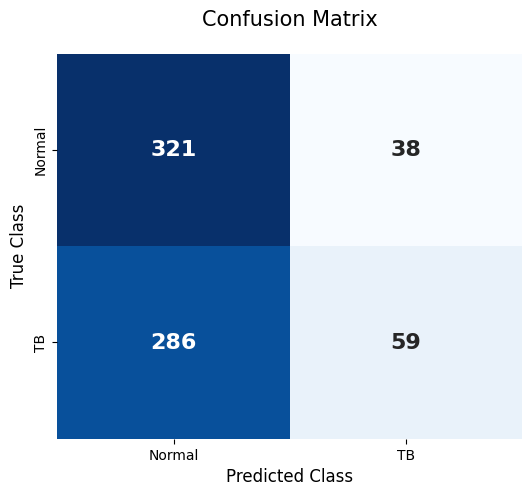

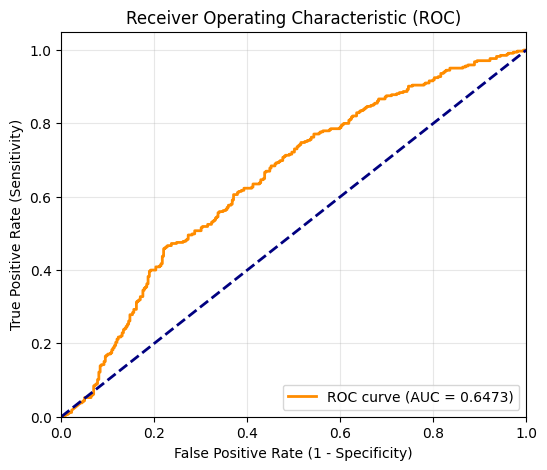

In [16]:
# saved as a state dict; no normalization was used for this checkpoint
custom_cnn_4200_transform = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor()
])

PATH = os.path.join(path_classification, 'class_ex3_run4_4200.pt')

model = CNN().to(device)
state_dict = torch.load(PATH, map_location=device)
model.load_state_dict(state_dict)
model.eval()

test_dl = DataLoader(whole_dataset('./data_704', custom_cnn_4200_transform), batch_size=32)

predictions, probs, labels, metrics = model_predict_new(model, test_dl, device)
record(results_4200_to_704, 'Custom CNN', metrics)

## Trained on 704 -> evaluated on whole 4200

Prediction Metrics
Test Accuracy: 0.1662 | f1: 0.2850 | AUC: 0.5539
Sensitivity: 0.9971 | Specificity: 0.0000
Precision: 0.1663 | Test Time: 0.8848


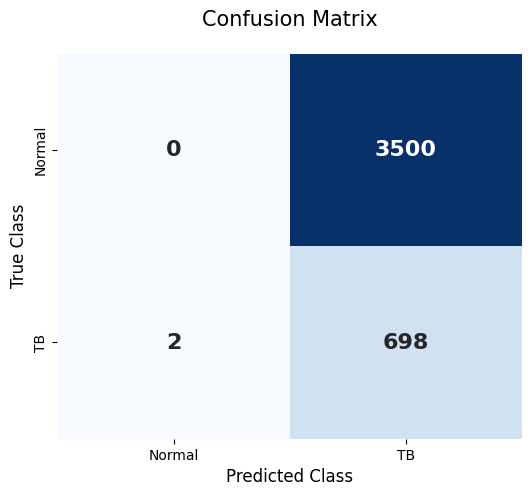

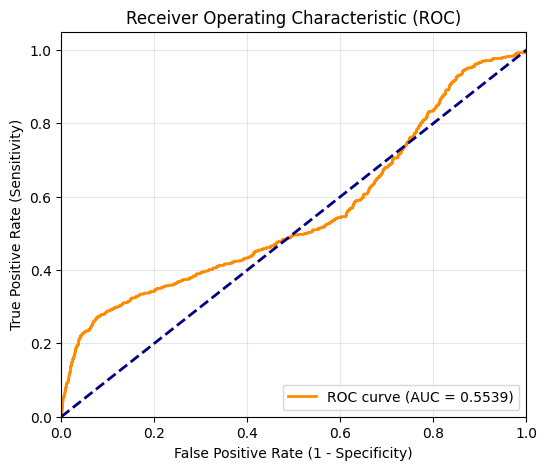

In [17]:
# saved as a full model object
custom_cnn_704_transform = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.2556, 0.2556, 0.2556])
])

PATH = os.path.join(path_classification, 'custom_run1_aug.pt')

model = torch.load(PATH, map_location=device, weights_only=False)
model.eval()

test_dl = DataLoader(whole_dataset('./data_4200', custom_cnn_704_transform), batch_size=32)

predictions, probs, labels, metrics = model_predict_new(model, test_dl, device)
record(results_704_to_4200, 'Custom CNN', metrics)

# DENSENET169

## Trained on 4200 -> evaluated on whole 704

Prediction Metrics
Test Accuracy: 0.5099 | f1: 0.0000 | AUC: 0.6588
Sensitivity: 0.0000 | Specificity: 1.0000
Precision: 0.0000 | Test Time: 1.9176


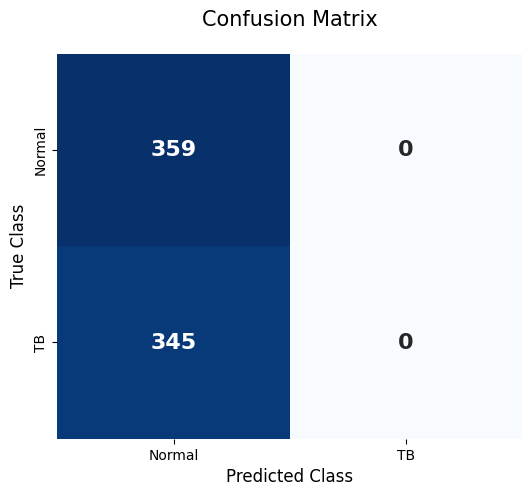

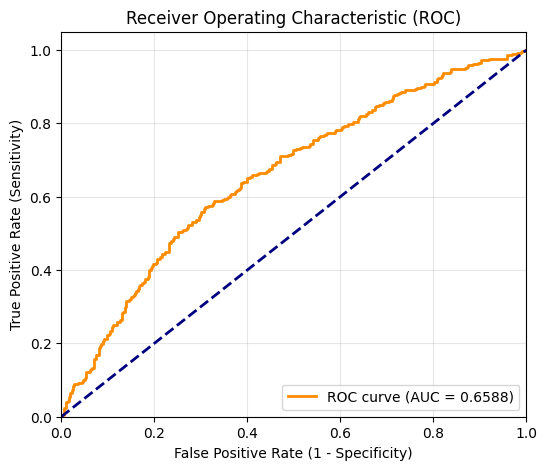

In [29]:
PATH = os.path.join(path_classification, 'densenet169_rahman_r5.pt')

model = torch.load(PATH, map_location=device, weights_only=False)
model.eval()

test_dl = DataLoader(whole_dataset('./data_704', imagenet_transform), batch_size=32)

predictions, probs, labels, metrics = model_predict_new(model, test_dl, device)
record(results_4200_to_704, 'DenseNet169', metrics)

## Trained on 704 -> evaluated on whole 4200

Prediction Metrics
Test Accuracy: 0.5764 | f1: 0.3075 | AUC: 0.6158
Sensitivity: 0.5643 | Specificity: 0.5789
Precision: 0.2113 | Test Time: 0.9929


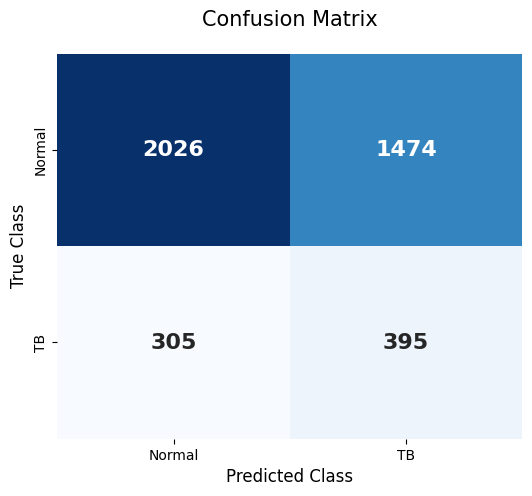

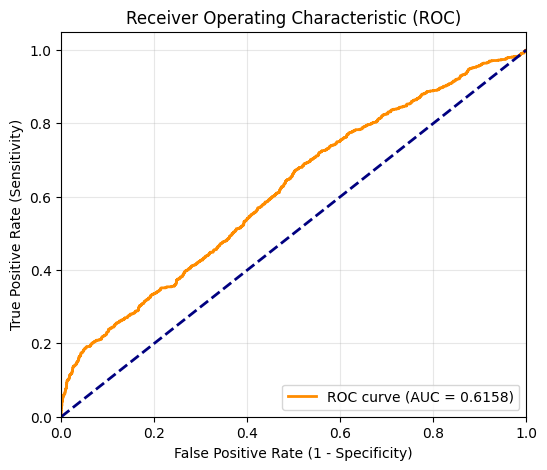

In [19]:
PATH = os.path.join(path_classification, 'densenet169_704_run2.pt')

model = torch.load(PATH, map_location=device, weights_only=False)
model.eval()

test_dl = DataLoader(whole_dataset('./data_4200', imagenet_transform), batch_size=32)

predictions, probs, labels, metrics = model_predict_new(model, test_dl, device)
record(results_704_to_4200, 'DenseNet169', metrics)

# VGG16

## Trained on 4200 -> evaluated on whole 704

Prediction Metrics
Test Accuracy: 0.5114 | f1: 0.0115 | AUC: 0.6231
Sensitivity: 0.0058 | Specificity: 0.9972
Precision: 0.6667 | Test Time: 1.9104


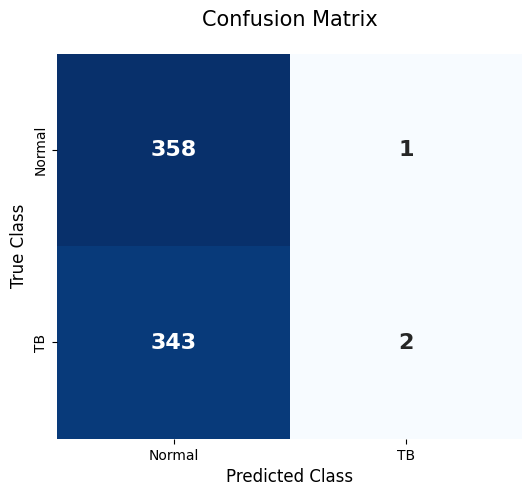

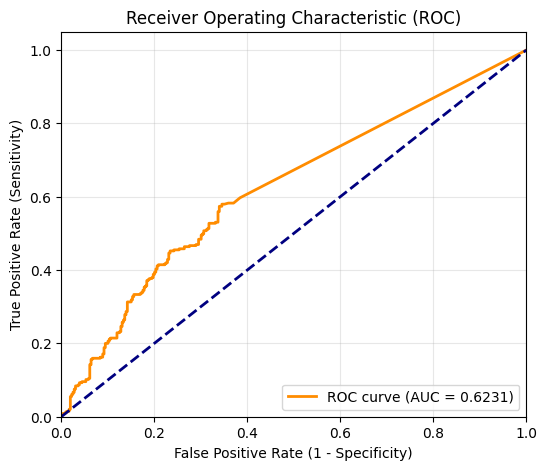

In [20]:
PATH = os.path.join(path_classification, 'vgg16_rahman_r3_2.pt')

model = torch.load(PATH, map_location=device, weights_only=False)
model.eval()

test_dl = DataLoader(whole_dataset('./data_704', imagenet_transform), batch_size=32)

predictions, probs, labels, metrics = model_predict_new(model, test_dl, device)
record(results_4200_to_704, 'VGG16', metrics)

## Trained on 704 -> evaluated on whole 4200

Prediction Metrics
Test Accuracy: 0.6017 | f1: 0.4019 | AUC: 0.7828
Sensitivity: 0.8029 | Specificity: 0.5614
Precision: 0.2680 | Test Time: 1.0558


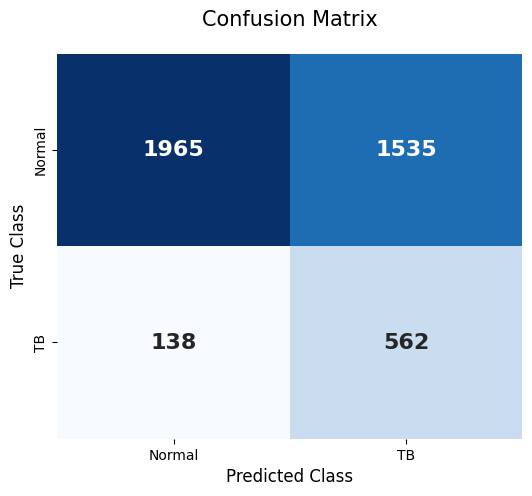

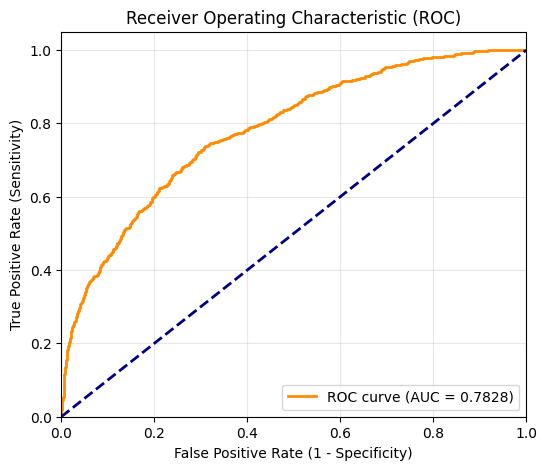

In [21]:
PATH = os.path.join(path_classification, 'vgg16_class_704.pt')

model = torch.load(PATH, map_location=device, weights_only=False)
model.eval()

test_dl = DataLoader(whole_dataset('./data_4200', imagenet_transform), batch_size=32)

predictions, probs, labels, metrics = model_predict_new(model, test_dl, device)
record(results_704_to_4200, 'VGG16', metrics)

# RESNET50

## Trained on 4200 -> evaluated on whole 704

Prediction Metrics
Test Accuracy: 0.5142 | f1: 0.0172 | AUC: 0.7119
Sensitivity: 0.0087 | Specificity: 1.0000
Precision: 1.0000 | Test Time: 1.8862


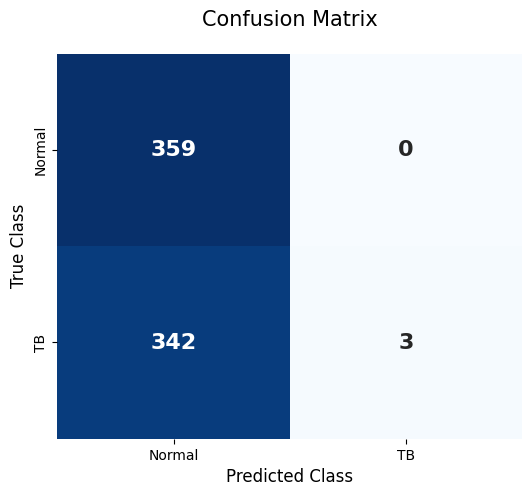

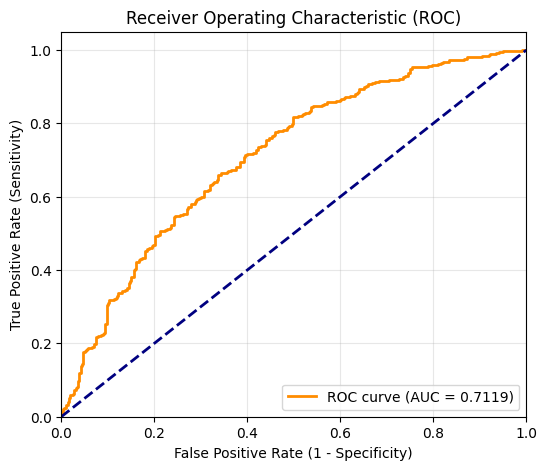

In [22]:
PATH = os.path.join(path_classification, 'resnet50_rahman_r5.pt')

model = torch.load(PATH, map_location=device, weights_only=False)
model.eval()

test_dl = DataLoader(whole_dataset('./data_704', imagenet_transform), batch_size=32)

predictions, probs, labels, metrics = model_predict_new(model, test_dl, device)
record(results_4200_to_704, 'ResNet50', metrics)

## Trained on 704 -> evaluated on whole 4200

Prediction Metrics
Test Accuracy: 0.5010 | f1: 0.1895 | AUC: 0.3376
Sensitivity: 0.3500 | Specificity: 0.5311
Precision: 0.1299 | Test Time: 0.9413


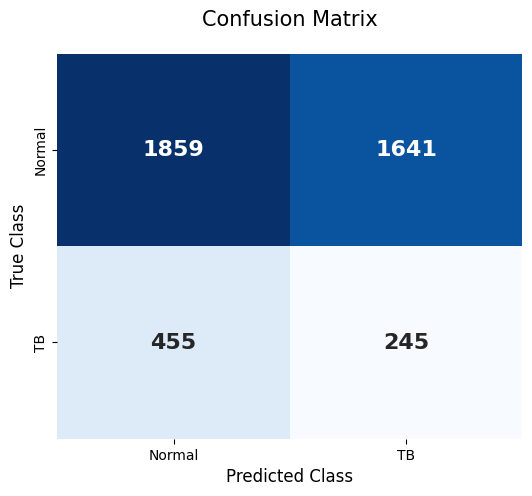

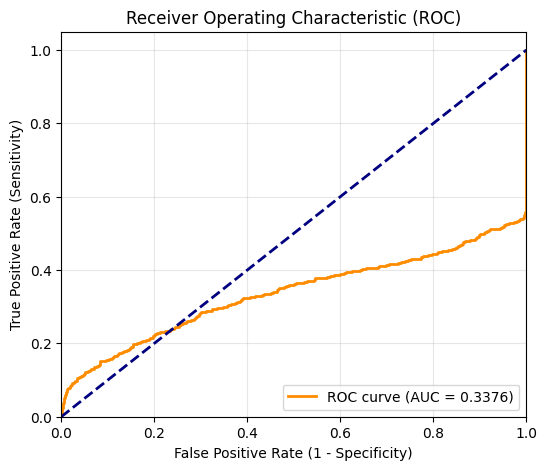

In [23]:
PATH = os.path.join(path_classification, 'resnet50_704_run2.pt')

model = torch.load(PATH, map_location=device, weights_only=False)
model.eval()

test_dl = DataLoader(whole_dataset('./data_4200', imagenet_transform), batch_size=32)

predictions, probs, labels, metrics = model_predict_new(model, test_dl, device)
record(results_704_to_4200, 'ResNet50', metrics)

# EFFICIENTNET B3

## Trained on 4200 -> evaluated on whole 704

Prediction Metrics
Test Accuracy: 0.5384 | f1: 0.1425 | AUC: 0.5332
Sensitivity: 0.0783 | Specificity: 0.9805
Precision: 0.7941 | Test Time: 1.9598


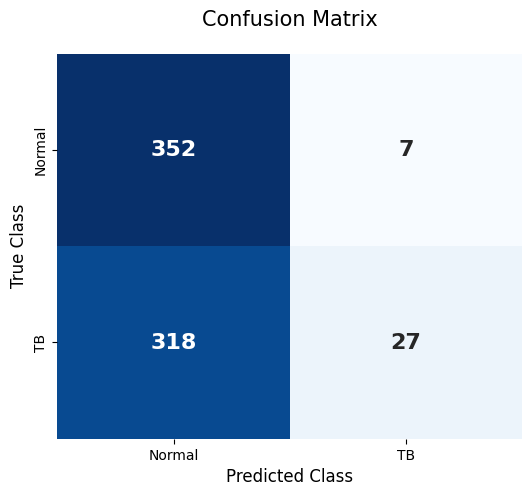

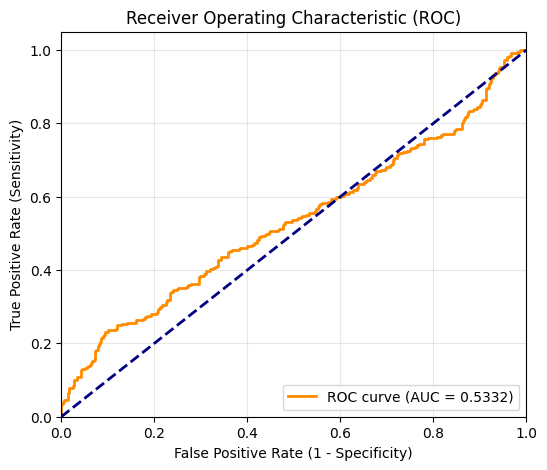

In [24]:
PATH = os.path.join(path_classification, 'efficient_net_4200_run3.pt')

model = torch.load(PATH, map_location=device, weights_only=False)
model.eval()

test_dl = DataLoader(whole_dataset('./data_704', imagenet_transform), batch_size=32)

predictions, probs, labels, metrics = model_predict_new(model, test_dl, device)
record(results_4200_to_704, 'EfficientNetB3', metrics)

## Trained on 704 -> evaluated on whole 4200

Prediction Metrics
Test Accuracy: 0.7374 | f1: 0.3916 | AUC: 0.6286
Sensitivity: 0.5071 | Specificity: 0.7834
Precision: 0.3190 | Test Time: 0.9340


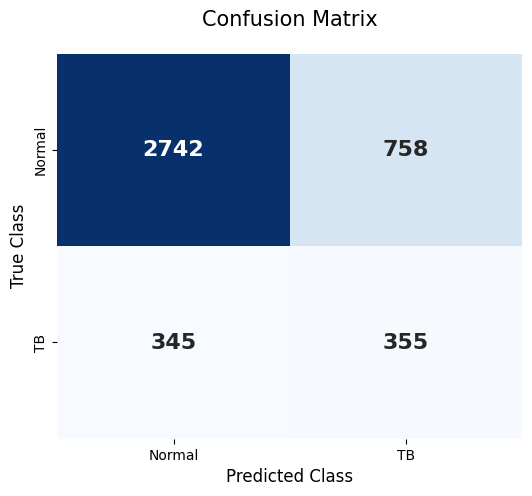

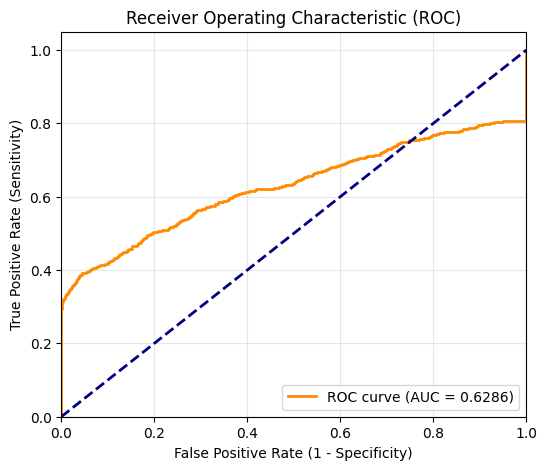

In [25]:
PATH = os.path.join(path_classification, 'efficient_net_704_run2.pt')

model = torch.load(PATH, map_location=device, weights_only=False)
model.eval()

test_dl = DataLoader(whole_dataset('./data_4200', imagenet_transform), batch_size=32)

predictions, probs, labels, metrics = model_predict_new(model, test_dl, device)
record(results_704_to_4200, 'EfficientNetB3', metrics)

# SUMMARY TABLES

In [26]:
import pandas as pd

df_4200_to_704 = pd.DataFrame(results_4200_to_704).set_index('Model')
print('Table 1: Models trained on the 4200 dataset, evaluated on the whole 704 dataset')
display(df_4200_to_704.round(4))

Table 1: Models trained on the 4200 dataset, evaluated on the whole 704 dataset


,Acc.,Prec.,Sens.,F1,Spec.,AUC
Model,,,,,,
Custom CNN,0.5398,0.6082,0.1710,0.2670,0.8942,0.6473
DenseNet169,0.5099,0.0000,0.0000,0.0000,1.0000,0.6588
VGG16,0.5114,0.6667,0.0058,0.0115,0.9972,0.6231
ResNet50,0.5142,1.0000,0.0087,0.0172,1.0000,0.7119
EfficientNetB3,0.5384,0.7941,0.0783,0.1425,0.9805,0.5332


In [27]:
df_704_to_4200 = pd.DataFrame(results_704_to_4200).set_index('Model')
print('Table 2: Models trained on the 704 dataset, evaluated on the whole 4200 dataset')
display(df_704_to_4200.round(4))

Table 2: Models trained on the 704 dataset, evaluated on the whole 4200 dataset


,Acc.,Prec.,Sens.,F1,Spec.,AUC
Model,,,,,,
Custom CNN,0.1662,0.1663,0.9971,0.2850,0.0000,0.5539
DenseNet169,0.5764,0.2113,0.5643,0.3075,0.5789,0.6158
VGG16,0.6017,0.2680,0.8029,0.4019,0.5614,0.7828
ResNet50,0.5010,0.1299,0.3500,0.1895,0.5311,0.3376
EfficientNetB3,0.7374,0.3190,0.5071,0.3916,0.7834,0.6286


# RECOMPUTED METRICS AND F1 CONFIDENCE INTERVALS

This section recomputes the full metric set (Acc., Prec., Sens., F1, Spec., AUC) from
scratch and adds a 95% confidence interval for the F1-score of the TB class.

- **Task 1 — D2 in-domain.** 4 training schemes (No Aug., With Aug., Oversampling,
  Segmented) x 5 architectures, each evaluated on the **D2 test split only**.
- **Task 2 — Cross-dataset D1 -> D2.** The 5 models trained on D1 (704 images),
  each evaluated on the **whole** D2 dataset (train + val + test, n = 4200).

**Confidence intervals.** B = 10,000 percentile bootstrap resamples of the saved
prediction arrays (`np.random.default_rng(seed=42)`, 2.5th / 97.5th percentiles).
Inference is run once per model; only the arrays are resampled. Where a model is
flawless on the test split every replicate is identical and the bootstrap CI
collapses to [1.0, 1.0]; those rows fall back to a **Wilson score CI on accuracy**
and are flagged in the `CI_method` column.

**Note on the segmented scheme.** The segmented models were not trained on the
80/10/10 split built by `create_images_folder_4200`. At training time the whole
dataset was segmented first (flat `Images/` folder), and the resulting ROI images
were then split **70/20/10** by `setup_roi_database_4200`, ordered by
`os.listdir()` of the ROI folders rather than by the metadata spreadsheets. Both
splits leave 10% for test, so the test set is the same *size* (420 = 70 TB + 350
Normal) but not the same *images*. The pipeline below reproduces the segmented
route exactly as written; the test-set composition of every scheme is printed and
cross-checked at the end of Task 1.

## Setup: bootstrap and Wilson helpers

In [ ]:
# Extra imports for this section (the rest are already imported at the top).
import numpy as np
from sklearn.metrics import confusion_matrix

# --- bootstrap / Wilson settings -------------------------------------------
B_RESAMPLES = 10000          # number of bootstrap resamples
BOOT_SEED = 42               # np.random.default_rng seed
Z_95 = 1.96                  # normal quantile for a 95% interval


def bootstrap_f1_ci(y_true, y_pred, B=B_RESAMPLES, seed=BOOT_SEED):
    """Percentile bootstrap 95% CI for the F1-score of the positive (TB) class.

    The model is never re-run: this resamples the saved prediction arrays with
    replacement. F1 is rebuilt from TP/FP/FN counts with numpy rather than
    calling sklearn 10,000 times, and the resample indices are drawn one
    iteration at a time so memory stays flat even at n = 4200.

    Returns (ci_low, ci_high, replicates).
    """
    y_true = np.asarray(y_true).astype(np.int64)
    y_pred = np.asarray(y_pred).astype(np.int64)
    n = len(y_true)

    # per-sample indicators, so a resample is just a sum over the sampled indices
    tp_i = ((y_true == 1) & (y_pred == 1)).astype(np.int64)
    fp_i = ((y_true == 0) & (y_pred == 1)).astype(np.int64)
    fn_i = ((y_true == 1) & (y_pred == 0)).astype(np.int64)

    rng = np.random.default_rng(seed)
    reps = np.empty(B, dtype=np.float64)

    for b in range(B):
        idx = rng.integers(0, n, size=n)
        tp = tp_i[idx].sum()
        fp = fp_i[idx].sum()
        fn = fn_i[idx].sum()
        denom = 2 * tp + fp + fn
        # denom == 0 means the resample contains no TB image and no TB
        # prediction, so F1 is undefined; scored as 0 to match zero_division=0
        reps[b] = (2 * tp / denom) if denom > 0 else 0.0

    return float(np.percentile(reps, 2.5)), float(np.percentile(reps, 97.5)), reps


def wilson_acc_ci(n_correct, n, z=Z_95):
    """Wilson score 95% CI for accuracy.

    Used for rows where every bootstrap replicate is identical (a flawless
    classifier resamples to a flawless classifier, so the bootstrap CI
    degenerates to a single point and carries no information).
    """
    p = n_correct / n
    centre = (p + z ** 2 / (2 * n)) / (1 + z ** 2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / (1 + z ** 2 / n)
    return float(centre - half), float(centre + half)


## Setup: inference and metric helpers

In [ ]:
def predict_arrays(model, data_loader, device):
    """One inference pass. Returns (y_true, y_pred, y_prob) as numpy arrays,
    y_prob being the softmax probability of the positive (TB) class."""
    model.to(device)
    model.eval()

    y_true, y_pred, y_prob = [], [], []
    with torch.no_grad():
        for images, targets in data_loader:
            logits = model(images.to(device))
            y_pred.append(logits.argmax(dim=1).cpu())
            y_prob.append(F.softmax(logits, dim=1)[:, 1].cpu())
            y_true.append(targets)

    return (torch.cat(y_true).numpy(),
            torch.cat(y_pred).numpy(),
            torch.cat(y_prob).numpy())


# columns of the output tables, in the order used by the summary tables above
METRIC_COLS = ['Acc.', 'Prec.', 'Sens.', 'F1', 'Spec.', 'AUC',
               'F1_CI_low', 'F1_CI_high', 'CI_method']


def metrics_with_ci(y_true, y_pred, y_prob, label=''):
    """Full metric set plus a 95% CI for F1. Prints a clean block and returns a
    row dict. Keys prefixed with '_' are bookkeeping, not table columns."""
    n = len(y_true)
    n_tb = int((y_true == 1).sum())
    n_normal = int((y_true == 0).sum())
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

    # zero_division=0 keeps the ill-defined case explicit rather than raising
    acc = float((y_pred == y_true).mean())
    prec = precision_score(y_true, y_pred, zero_division=0)
    sens = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    spec = recall_score(y_true, y_pred, pos_label=0, zero_division=0)
    auc = roc_auc_score(y_true, y_prob)

    ci_low, ci_high, reps = bootstrap_f1_ci(y_true, y_pred)
    if np.ptp(reps) == 0:
        # every replicate identical -> bootstrap CI is degenerate, fall back
        ci_low, ci_high = wilson_acc_ci(int((y_pred == y_true).sum()), n)
        method = 'Wilson-acc (bootstrap degenerate)'
    else:
        method = 'bootstrap'

    print(f'--- {label} ---')
    print(f'Test set: n = {n} | TB = {n_tb} | Normal = {n_normal}')
    print(f'Confusion matrix: TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}')
    print(f'Acc. = {acc:.4f} | Prec. = {prec:.4f} | Sens. = {sens:.4f} | '
          f'F1 = {f1:.4f} | Spec. = {spec:.4f} | AUC = {auc:.4f}')
    print(f'F1 95% CI = [{ci_low:.4f}, {ci_high:.4f}]  ({method})')
    if method.startswith('Wilson'):
        print('    ^ all 10,000 bootstrap replicates were identical; the interval '
              'above is a Wilson CI on ACCURACY, not on F1.')
    print()

    return {
        'Acc.': acc, 'Prec.': prec, 'Sens.': sens, 'F1': f1,
        'Spec.': spec, 'AUC': auc,
        'F1_CI_low': ci_low, 'F1_CI_high': ci_high, 'CI_method': method,
        '_n': n, '_n_TB': n_tb, '_n_Normal': n_normal,
    }


## Setup: transforms, model loading and configuration

In [ ]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Every checkpoint was evaluated at training time with one of these four
# transforms; using the wrong one silently changes the metrics.
TRANSFORMS = {
    # ImageNet backbones on full (unsegmented) chest X-rays
    'imagenet': imagenet_transform,
    # Custom CNN trained on D2: resized, but never normalized
    'custom_4200': T.Compose([
        T.Resize((224, 224)),
        T.ToTensor(),
    ]),
    # Custom CNN trained on D1
    'custom_704': T.Compose([
        T.Resize((224, 224)),
        T.ToTensor(),
        T.Normalize(mean=IMAGENET_MEAN, std=[0.2556, 0.2556, 0.2556]),
    ]),
    # Segmented scheme: the ROI images come out of the U-Net already at
    # 224x224, so no Resize was applied at training time
    'imagenet_seg': T.Compose([
        T.ToTensor(),
        T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ]),
    # Segmented custom CNN: no Resize and no Normalize
    'custom_seg': T.Compose([
        T.ToTensor(),
    ]),
}

path_segmentation = '/content/drive/MyDrive/MSc Data Science/Thesis/Codes/segmentation'


def load_classifier(entry, device):
    """Loads a checkpoint according to how it was saved.

    'state_dict' -> the unsegmented custom CNN 4200 runs, which were saved with
    torch.save(model.state_dict(), ...) and need the CNN class defined above.
    'full'       -> everything else, saved as a complete model object.
    """
    root = entry.get('root', path_classification)
    path = os.path.join(root, entry['file'])

    if entry['load'] == 'state_dict':
        model = CNN().to(device)
        model.load_state_dict(torch.load(path, map_location=device))
    else:
        model = torch.load(path, map_location=device, weights_only=False)

    model.to(device)
    model.eval()
    return model


def evaluate_checkpoint(entry, data_dir, label, whole=False, batch_size=32):
    """Loads a checkpoint, runs inference once over the requested data, and
    returns the metric row (including the F1 CI).

    whole=False -> data_dir is a single ImageFolder (a test split)
    whole=True  -> data_dir is a dataset root, train + val + test concatenated
    """
    transform = TRANSFORMS[entry['tf']]
    dataset = (whole_dataset(data_dir, transform) if whole
               else ImageFolder(root=data_dir, transform=transform))
    data_loader = DataLoader(dataset, batch_size=batch_size)

    model = load_classifier(entry, device)
    y_true, y_pred, y_prob = predict_arrays(model, data_loader, device)

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return metrics_with_ci(y_true, y_pred, y_prob, label=label)


In [ ]:
# ---------------------------------------------------------------------------
# CONFIGURATION: every checkpoint used in this section
# ---------------------------------------------------------------------------
# 'file'  checkpoint name
# 'root'  parent folder (defaults to path_classification)
# 'load'  'state_dict' or 'full' (see load_classifier)
# 'tf'    key into TRANSFORMS

D2_TEST_DIR = './data_4200/test'          # 80/10/10 split, built earlier
D2_SEG_TEST_DIR = './data_4200_seg/test'  # 70/20/10 ROI split, built below
D2_ROOT = './data_4200'                   # for the whole-dataset evaluation

CONFIG_TASK1 = {
    'No Aug.': {
        'data_dir': D2_TEST_DIR,
        'models': {
            'Custom CNN':     {'file': 'class_ex3_run1_4200.pt',      'load': 'state_dict', 'tf': 'custom_4200'},
            'DenseNet169':    {'file': 'densenet169_rahman_r2_redo.pt', 'load': 'full',     'tf': 'imagenet'},
            'VGG16':          {'file': 'vgg16_rahman_r1_redo_2.pt',   'load': 'full',       'tf': 'imagenet'},
            'ResNet50':       {'file': 'resnet50_rahman_r3.pt',       'load': 'full',       'tf': 'imagenet'},
            'EfficientNetB3': {'file': 'efficient_net_4200_redo_2.pt', 'load': 'full',      'tf': 'imagenet'},
        },
    },
    'With Aug.': {
        'data_dir': D2_TEST_DIR,
        'models': {
            'Custom CNN':     {'file': 'class_ex3_run2_4200.pt',      'load': 'state_dict', 'tf': 'custom_4200'},
            'DenseNet169':    {'file': 'densenet169_rahman_r4.pt',    'load': 'full',       'tf': 'imagenet'},
            'VGG16':          {'file': 'vgg16_rahman_r2.pt',          'load': 'full',       'tf': 'imagenet'},
            'ResNet50':       {'file': 'resnet50_rahman_r4.pt',       'load': 'full',       'tf': 'imagenet'},
            'EfficientNetB3': {'file': 'efficient_net_4200_run2.pt',  'load': 'full',       'tf': 'imagenet'},
        },
    },
    'Oversampling': {
        'data_dir': D2_TEST_DIR,
        'models': {
            'Custom CNN':     {'file': 'class_ex3_run4_4200.pt',      'load': 'state_dict', 'tf': 'custom_4200'},
            'DenseNet169':    {'file': 'densenet169_rahman_r5.pt',    'load': 'full',       'tf': 'imagenet'},
            'VGG16':          {'file': 'vgg16_rahman_r3_2.pt',        'load': 'full',       'tf': 'imagenet'},
            'ResNet50':       {'file': 'resnet50_rahman_r5.pt',       'load': 'full',       'tf': 'imagenet'},
            'EfficientNetB3': {'file': 'efficient_net_4200_run3.pt',  'load': 'full',       'tf': 'imagenet'},
        },
    },
    'Segmented': {
        'data_dir': D2_SEG_TEST_DIR,
        'models': {
            # the segmented custom CNN was saved as a full object, unlike the
            # unsegmented ones, and was trained without normalization
            'Custom CNN':     {'file': 'class_seg_3cnn_4200.pt',        'load': 'full', 'tf': 'custom_seg'},
            'DenseNet169':    {'file': 'densenet169_class_seg_rahman.pt', 'load': 'full', 'tf': 'imagenet_seg'},
            # this one lives in the segmentation folder, not the classification one
            'VGG16':          {'file': 'vgg16_class_seg_4200.pt', 'root': path_segmentation, 'load': 'full', 'tf': 'imagenet_seg'},
            'ResNet50':       {'file': 'resnet50_class_seg_4200.pt',    'load': 'full', 'tf': 'imagenet_seg'},
            'EfficientNetB3': {'file': 'enet_class_seg_4200.pt',        'load': 'full', 'tf': 'imagenet_seg'},
        },
    },
}

# Models trained on D1 (704), evaluated on the whole of D2
CONFIG_TASK2 = {
    'Custom CNN':     {'file': 'custom_run1_aug.pt',        'load': 'full', 'tf': 'custom_704'},
    'DenseNet169':    {'file': 'densenet169_704_run2.pt',   'load': 'full', 'tf': 'imagenet'},
    'VGG16':          {'file': 'vgg16_class_704.pt',        'load': 'full', 'tf': 'imagenet'},
    'ResNet50':       {'file': 'resnet50_704_run2.pt',      'load': 'full', 'tf': 'imagenet'},
    'EfficientNetB3': {'file': 'efficient_net_704_run2.pt', 'load': 'full', 'tf': 'imagenet'},
}

# Results are kept in dicts keyed by (scheme, model) / model, so re-running an
# individual cell overwrites its row instead of appending a duplicate.
results_task1 = {}
results_task2 = {}


def run_task1(scheme, model_name):
    """Evaluates one (scheme, model) pair on the D2 test split."""
    cfg = CONFIG_TASK1[scheme]
    row = evaluate_checkpoint(cfg['models'][model_name], cfg['data_dir'],
                              label=f'{scheme} | {model_name}')
    results_task1[(scheme, model_name)] = row
    return row


def run_task2(model_name):
    """Evaluates one D1-trained model on the whole D2 dataset (n = 4200)."""
    row = evaluate_checkpoint(CONFIG_TASK2[model_name], D2_ROOT,
                              label=f'D1 -> D2 | {model_name}', whole=True)
    results_task2[model_name] = row
    return row


## Building the segmented (ROI) version of D2

Reproduction of the "SEGMENT 4200" pipeline from `DenseNet169.ipynb`: every D2
image is copied into a flat `Images` folder, the whole lot is passed through the
trained U-Net (`seg_unet_2.pth`), each image is multiplied by its predicted lung
mask (hard attention), and only then are the ROI images split into
train/val/test.

Run these five cells once, before the Segmented cells of Task 1.

In [ ]:
def create_flat_images_4200(path, base_dir='./Images_4200'):
    """Copies every D2 image into base_dir/{tb,no_tb} with no train/val/test
    split, exactly as the segmentation step of DenseNet169.ipynb does. The whole
    dataset is segmented first; the split happens afterwards, on the ROI images."""

    tb_md = pd.read_excel(os.path.join(path, 'TB_Chest_Radiography_Database', 'Tuberculosis.metadata.xlsx'))
    no_tb_md = pd.read_excel(os.path.join(path, 'TB_Chest_Radiography_Database', 'Normal.metadata.xlsx'))

    img_id1 = list(tb_md['FILE NAME'])
    img_id0 = list(no_tb_md['FILE NAME'])

    print(f'# of TB images: {len(img_id1)}')
    print(f'# of Normal images: {len(img_id0)}')
    print(f'Total: {len(img_id1) + len(img_id0)}')

    for klas in ['tb', 'no_tb']:
        os.makedirs(os.path.join(base_dir, klas), exist_ok=True)

    path_tb_images = os.path.join(path, 'TB_Chest_Radiography_Database', 'Tuberculosis')
    path_no_tb_images = os.path.join(path, 'TB_Chest_Radiography_Database', 'Normal')

    print('Copying images...')
    for i in img_id1:
        str_i = str(i) + '.png'
        shutil.copy(src=os.path.join(path_tb_images, str_i),
                    dst=os.path.join(base_dir, 'tb', str_i))

    for i in img_id0:
        str_i = str(i) + '.png'
        shutil.copy(src=os.path.join(path_no_tb_images, str_i),
                    dst=os.path.join(base_dir, 'no_tb', str_i))

    print(f'Successfully created {base_dir}/tb and {base_dir}/no_tb')


create_flat_images_4200(path_rahman, base_dir='./Images_4200')


In [ ]:
# --- the U-Net used for segmentation (VGG16-BN encoder), as trained ---------
from torchvision.models import vgg16_bn


def conv(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True)
    )


def up_conv(in_channels, out_channels):
    return nn.Sequential(
        nn.ConvTranspose2d(in_channels, out_channels, kernel_size=2, stride=2),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True)
    )


class UNet(nn.Module):

    def __init__(self, num_classes=2):
        super().__init__()

        self.encoder = vgg16_bn(weights='DEFAULT').features

        self.block1 = nn.Sequential(*self.encoder[:6])
        self.block2 = nn.Sequential(*self.encoder[6:13])
        self.block3 = nn.Sequential(*self.encoder[13:20])
        self.block4 = nn.Sequential(*self.encoder[20:27])
        self.block5 = nn.Sequential(*self.encoder[27:34])

        self.bottleneck = nn.Sequential(*self.encoder[34:])
        self.conv_bottleneck = conv(512, 1024)

        self.up_conv6 = up_conv(1024, 512)
        self.conv6 = conv(512 + 512, 512)
        self.up_conv7 = up_conv(512, 256)
        self.conv7 = conv(256 + 512, 256)
        self.up_conv8 = up_conv(256, 128)
        self.conv8 = conv(128 + 256, 128)
        self.up_conv9 = up_conv(128, 64)
        self.conv9 = conv(64 + 128, 64)
        self.up_conv10 = up_conv(64, 32)
        self.conv10 = conv(32 + 64, 32)

        self.conv11 = nn.Conv2d(32, num_classes, kernel_size=1)

    def forward(self, x):
        block1 = self.block1(x)
        block2 = self.block2(block1)
        block3 = self.block3(block2)
        block4 = self.block4(block3)
        block5 = self.block5(block4)

        bottleneck = self.bottleneck(block5)
        x = self.conv_bottleneck(bottleneck)

        x = self.up_conv6(x)
        x = torch.cat([x, block5], dim=1)
        x = self.conv6(x)

        x = self.up_conv7(x)
        x = torch.cat([x, block4], dim=1)
        x = self.conv7(x)

        x = self.up_conv8(x)
        x = torch.cat([x, block3], dim=1)
        x = self.conv8(x)

        x = self.up_conv9(x)
        x = torch.cat([x, block2], dim=1)
        x = self.conv9(x)

        x = self.up_conv10(x)
        x = torch.cat([x, block1], dim=1)
        x = self.conv10(x)

        return self.conv11(x)


# the checkpoint used for the segmented experiments
seg_model_path = os.path.join(path_segmentation, 'seg_unet_2.pth')

unet = UNet()
unet.load_state_dict(torch.load(seg_model_path, map_location=device))
unet.to(device)
print(f'Loaded U-Net from {seg_model_path}')


In [ ]:
# --- dataset that yields (original, normalized, label, filename) ------------
from torch.utils.data import Dataset
from torchvision.transforms import v2 as Tv2
import PIL


class ROI(Dataset):
    """Returns a tensor object that can be batched for segmentation inference.

    The normalized copy feeds the U-Net; the un-normalized copy is what the
    predicted mask is applied to, so the saved ROI keeps the original intensities.
    """

    def __init__(self, root_dir):
        # transforms used by the segmentation model at eval time, not training
        self.transforms_norm = Tv2.Compose([
            Tv2.Resize((224, 224)),
            Tv2.ToImage(),
            Tv2.ToDtype(torch.float32, scale=True),
            Tv2.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
        ])

        self.transforms_orig = Tv2.Compose([
            Tv2.Resize((224, 224)),
            Tv2.ToImage(),
            Tv2.ToDtype(torch.float32, scale=True),
        ])

        self.root_dir = root_dir

        im_id0 = os.listdir(os.path.join(self.root_dir, 'no_tb'))
        im_id1 = os.listdir(os.path.join(self.root_dir, 'tb'))

        self.im_data = []
        for f in im_id0:
            self.im_data.append(('no_tb', f, 0))
        for f in im_id1:
            self.im_data.append(('tb', f, 1))

    def __len__(self):
        return len(self.im_data)

    def __getitem__(self, idx):
        im_path = os.path.join(self.root_dir, self.im_data[idx][0], self.im_data[idx][1])
        label = torch.tensor(self.im_data[idx][2]).long()
        im_name = self.im_data[idx][1]

        image = PIL.Image.open(im_path).convert('RGB')

        return self.transforms_orig(image), self.transforms_norm(image), label, im_name


seg_td = ROI('./Images_4200')
seg_dl = DataLoader(seg_td, batch_size=64)

print(f'Number of batches: {len(seg_dl)}')
print(f'Number of Images: {len(seg_dl.dataset)}')


In [ ]:
from torchvision.utils import save_image


def segmentation_inference(model, data_loader, device, roi_dir):
    """Predicts a lung mask for every image and saves image * mask (hard
    attention), preserving the original file names."""

    model.to(device)
    model.eval()

    os.makedirs(os.path.join(roi_dir, 'tb'), exist_ok=True)
    os.makedirs(os.path.join(roi_dir, 'no_tb'), exist_ok=True)

    print(f'Starting inference. Saving images to {roi_dir}...')
    start_time = time.time()

    with torch.no_grad():
        for batch_idx, batch in enumerate(data_loader):

            images_orig = batch[0].to(device)
            images_norm = batch[1].to(device)
            label_batch = batch[2]
            img_name_batch = batch[3]

            masks = model(images_norm)
            pred_masks = masks.argmax(dim=1)
            roi_batch = images_orig * pred_masks.unsqueeze(1)

            for i in range(len(roi_batch)):
                img = roi_batch[i]
                img_name = img_name_batch[i]
                folder = 'tb' if label_batch[i].item() == 1 else 'no_tb'
                save_image(img, os.path.join(roi_dir, folder, img_name), normalize=True)

            if (batch_idx + 1) % 5 == 0:
                elapsed_mins = (time.time() - start_time) / 60
                print(f'Finished batch {batch_idx + 1}. Time elapsed: {elapsed_mins:.2f} min')

    total_time = (time.time() - start_time) / 60
    print(f'Done! Total Inference time: {total_time:.2f} minutes')


segmentation_inference(unet, seg_dl, device, './ROI_Images_4200')


In [ ]:
def setup_roi_test_split_4200(path, base_dir='./data_4200_seg'):
    """Reproduces the split of setup_roi_database_4200 from the training
    notebooks. Two things differ from create_images_folder_4200 and are kept
    exactly as they were at training time:

      * the ratios are 70/20/10, not 80/10/10
      * the ordering comes from os.listdir() on the ROI folders, not from the
        metadata spreadsheets

    Only the test folder is materialised (train and val are not needed for
    evaluation); the slicing itself is unchanged, so the test images are the
    same ones the segmented models were tested on.
    """
    roi_0 = os.listdir(os.path.join(path, 'no_tb'))
    roi_1 = os.listdir(os.path.join(path, 'tb'))

    print('Splitting Details')
    print(f'# of TB images: {len(roi_1)}')
    print(f'# of Normal images: {len(roi_0)}')
    print(f'Total: {len(roi_1) + len(roi_0)}')

    train_ratio = 0.7
    val_ratio = 0.2

    train_no_1 = int(train_ratio * len(roi_1))
    train_no_0 = int(train_ratio * len(roi_0))

    val_no_1 = int(val_ratio * len(roi_1))
    val_no_0 = int(val_ratio * len(roi_0))

    train_1 = roi_1[:train_no_1]
    train_0 = roi_0[:train_no_0]
    print(f'Train set #: {len(train_1) + len(train_0)}')

    val_1 = roi_1[train_no_1:train_no_1 + val_no_1]
    val_0 = roi_0[train_no_0:train_no_0 + val_no_0]
    print(f'Validation set #: {len(val_1) + len(val_0)}')

    test_1 = roi_1[train_no_1 + val_no_1:]
    test_0 = roi_0[train_no_0 + val_no_0:]
    print(f'Test set #: {len(test_1) + len(test_0)}  '
          f'(TB: {len(test_1)}, Normal: {len(test_0)})')
    print()

    for klas in ['tb', 'no_tb']:
        os.makedirs(os.path.join(base_dir, 'test', klas), exist_ok=True)

    print('Copying test images...')
    for i in test_1:
        shutil.copy(src=os.path.join(path, 'tb', i),
                    dst=os.path.join(base_dir, 'test', 'tb', i))
    for i in test_0:
        shutil.copy(src=os.path.join(path, 'no_tb', i),
                    dst=os.path.join(base_dir, 'test', 'no_tb', i))

    print(f'Successfully created {base_dir}/test')


setup_roi_test_split_4200('./ROI_Images_4200', base_dir='./data_4200_seg')


# TASK 1 — D2 IN-DOMAIN

Each cell below loads one checkpoint, runs inference on the **D2 test split only**
and prints the metric set, the test-set composition and the F1 confidence
interval. Cells are independent and can be re-run individually.

## Scheme: No Aug.

In [ ]:
# Scheme: No Aug.  |  Model: Custom CNN
_ = run_task1('No Aug.', 'Custom CNN')


In [ ]:
# Scheme: No Aug.  |  Model: DenseNet169
_ = run_task1('No Aug.', 'DenseNet169')


In [ ]:
# Scheme: No Aug.  |  Model: VGG16
_ = run_task1('No Aug.', 'VGG16')


In [ ]:
# Scheme: No Aug.  |  Model: ResNet50
_ = run_task1('No Aug.', 'ResNet50')


In [ ]:
# Scheme: No Aug.  |  Model: EfficientNetB3
_ = run_task1('No Aug.', 'EfficientNetB3')


## Scheme: With Aug.

In [ ]:
# Scheme: With Aug.  |  Model: Custom CNN
_ = run_task1('With Aug.', 'Custom CNN')


In [ ]:
# Scheme: With Aug.  |  Model: DenseNet169
_ = run_task1('With Aug.', 'DenseNet169')


In [ ]:
# Scheme: With Aug.  |  Model: VGG16
_ = run_task1('With Aug.', 'VGG16')


In [ ]:
# Scheme: With Aug.  |  Model: ResNet50
_ = run_task1('With Aug.', 'ResNet50')


In [ ]:
# Scheme: With Aug.  |  Model: EfficientNetB3
_ = run_task1('With Aug.', 'EfficientNetB3')


## Scheme: Oversampling

In [ ]:
# Scheme: Oversampling  |  Model: Custom CNN
_ = run_task1('Oversampling', 'Custom CNN')


In [ ]:
# Scheme: Oversampling  |  Model: DenseNet169
_ = run_task1('Oversampling', 'DenseNet169')


In [ ]:
# Scheme: Oversampling  |  Model: VGG16
_ = run_task1('Oversampling', 'VGG16')


In [ ]:
# Scheme: Oversampling  |  Model: ResNet50
_ = run_task1('Oversampling', 'ResNet50')


In [ ]:
# Scheme: Oversampling  |  Model: EfficientNetB3
_ = run_task1('Oversampling', 'EfficientNetB3')


## Scheme: Segmented

_Requires the ROI cells above to have been run (`./data_4200_seg/test`)._

In [ ]:
# Scheme: Segmented  |  Model: Custom CNN
_ = run_task1('Segmented', 'Custom CNN')


In [ ]:
# Scheme: Segmented  |  Model: DenseNet169
_ = run_task1('Segmented', 'DenseNet169')


In [ ]:
# Scheme: Segmented  |  Model: VGG16
_ = run_task1('Segmented', 'VGG16')


In [ ]:
# Scheme: Segmented  |  Model: ResNet50
_ = run_task1('Segmented', 'ResNet50')


In [ ]:
# Scheme: Segmented  |  Model: EfficientNetB3
_ = run_task1('Segmented', 'EfficientNetB3')


## Task 1 — summary table

In [ ]:
# (Scheme, Model) two-level index, columns in the same order as the tables above
rows = []
for (scheme, model_name), row in results_task1.items():
    rows.append({'Scheme': scheme, 'Model': model_name,
                 **{c: row[c] for c in METRIC_COLS}})

df_task1 = pd.DataFrame(rows).set_index(['Scheme', 'Model'])

# keep configuration order rather than execution order
order = [(s, m) for s in CONFIG_TASK1 for m in CONFIG_TASK1[s]['models']]
df_task1 = df_task1.reindex([k for k in order if k in df_task1.index])

print('Table 3: D2 in-domain results on the D2 test split, with 95% CIs for F1')
display(df_task1.round(4))


## Task 1 — test-set composition check

In [ ]:
# Explicitly report the test-set size and TB/Normal counts per scheme, and flag
# any disagreement between schemes rather than normalising it away.
comp = pd.DataFrame([
    {'Scheme': scheme, 'Model': model_name,
     'n': row['_n'], 'TB': row['_n_TB'], 'Normal': row['_n_Normal']}
    for (scheme, model_name), row in results_task1.items()
])
comp = comp.set_index(['Scheme', 'Model'])
print('Test-set composition per evaluated checkpoint')
display(comp)

print()
per_scheme = {}
for scheme in dict.fromkeys(s for s, _ in results_task1):
    sizes = {(r['_n'], r['_n_TB'], r['_n_Normal'])
             for (s, _), r in results_task1.items() if s == scheme}
    per_scheme[scheme] = sizes
    if len(sizes) > 1:
        print(f'WARNING: models within scheme "{scheme}" disagree on the test '
              f'set: {sorted(sizes)}')
    else:
        n, n_tb, n_norm = next(iter(sizes))
        print(f'{scheme:<14} n = {n}, TB = {n_tb}, Normal = {n_norm}')

print()
distinct = {next(iter(v)) for v in per_scheme.values() if len(v) == 1}
if len(per_scheme) and len(distinct) > 1:
    print('WARNING: the schemes DO NOT share the same test-set size / class '
          'balance. The numbers above are reported as computed; nothing has '
          'been normalised.')
    for scheme, sizes in per_scheme.items():
        print(f'  {scheme}: {sorted(sizes)}')
elif len(distinct) == 1:
    n, n_tb, n_norm = next(iter(distinct))
    print(f'All schemes agree on the test-set size: n = {n} '
          f'(TB = {n_tb}, Normal = {n_norm}).')
    print('Note: the Segmented scheme reaches the same size through a different '
          'route (70/20/10 on os.listdir order), so the images themselves are '
          'not necessarily the same as in the other three schemes.')


# TASK 2 — CROSS-DATASET D1 -> D2

The 5 models trained on D1 (704 images) evaluated on the **whole** D2 dataset
(train + val + test concatenated, n = 4200) via the existing `whole_dataset()`
helper. Same metric set, same bootstrap CIs.

In [ ]:
# D1-trained Custom CNN, evaluated on the whole of D2 (n = 4200)
_ = run_task2('Custom CNN')


In [ ]:
# D1-trained DenseNet169, evaluated on the whole of D2 (n = 4200)
_ = run_task2('DenseNet169')


In [ ]:
# D1-trained VGG16, evaluated on the whole of D2 (n = 4200)
_ = run_task2('VGG16')


In [ ]:
# D1-trained ResNet50, evaluated on the whole of D2 (n = 4200)
_ = run_task2('ResNet50')


In [ ]:
# D1-trained EfficientNetB3, evaluated on the whole of D2 (n = 4200)
_ = run_task2('EfficientNetB3')


## Task 2 — summary table

In [ ]:
df_task2 = pd.DataFrame([
    {'Model': model_name, **{c: row[c] for c in METRIC_COLS}}
    for model_name, row in results_task2.items()
]).set_index('Model')

# keep configuration order rather than execution order
df_task2 = df_task2.reindex([m for m in CONFIG_TASK2 if m in df_task2.index])

print('Table 4: Models trained on D1 (704), evaluated on the whole D2 dataset '
      '(n = 4200), with 95% CIs for F1')
display(df_task2.round(4))

print()
sizes = {(r['_n'], r['_n_TB'], r['_n_Normal']) for r in results_task2.values()}
for n, n_tb, n_norm in sorted(sizes):
    print(f'Evaluation set: n = {n}, TB = {n_tb}, Normal = {n_norm}')
if len(sizes) > 1:
    print('WARNING: the models disagree on the evaluation set size.')
